In [1]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.model_selection import cross_val_score, cross_val_predict
from sklearn.metrics import average_precision_score

import pandas as pd

from pm import config, data, split, models


df = data.load_processed()

train, _test = split.split_train_test(df)

feature_columns = config.BASIC_NUMERICAL_COLUMNS + config.PHYSICAL_NUMERICAL_COLUMNS + config.CATEGORICAL_COLUMNS

X = train[feature_columns]

y = train[config.LABEL]

groups = train[config.GROUPS]


In [2]:
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=config.SEED)

column_sets = {
    "basic": config.BASIC_NUMERICAL_COLUMNS,
    "basic + physical": config.BASIC_NUMERICAL_COLUMNS + config.PHYSICAL_NUMERICAL_COLUMNS,
}

spw = (y == 0).sum() / (y == 1).sum()

experiments = [
    ("logistic", lambda cols: models.build_logistic_pipeline(cols)),
    ("logistic balanced", lambda cols: models.build_logistic_pipeline(cols, class_weight="balanced")),
    ("random forest", lambda cols: models.build_random_forest_pipeline(cols)),
    ("random forest balanced", lambda cols: models.build_random_forest_pipeline(cols, class_weight="balanced")),
    ("xgboost", lambda cols: models.build_xgboost_pipeline(cols)),
    ("xgboost weighted", lambda cols: models.build_xgboost_pipeline(cols, scale_pos_weight=spw)),
]

results = []

for set_name, numeric_columns in column_sets.items():
    for exp_name, exp_pipeline_func in experiments:
        pipeline = exp_pipeline_func(numeric_columns)

        scores = cross_val_score(pipeline, X, y, cv=sgkf, groups=groups,
                                 scoring="average_precision")

        results.append({
            "columns": set_name,
            "model": exp_name,
            "pr_auc_mean": scores.mean(),
            "pr_auc_std": scores.std(),
            "scores": scores
        })

results = pd.DataFrame(results)
print(f"Random baseline (failure rate): {y.mean():.3f}")
print(results.round(3))


print()
print("Ranking by mean PR AUC:")
results = results.sort_values("pr_auc_mean", ascending=False)
print(results[["model", "columns", "pr_auc_mean", "pr_auc_std"]].round(3))

Random baseline (failure rate): 0.034
             columns                   model  pr_auc_mean  pr_auc_std  \
0              basic                logistic        0.464       0.052   
1              basic       logistic balanced        0.427       0.055   
2              basic           random forest        0.742       0.050   
3              basic  random forest balanced        0.697       0.050   
4              basic                 xgboost        0.746       0.053   
5              basic        xgboost weighted        0.731       0.065   
6   basic + physical                logistic        0.494       0.045   
7   basic + physical       logistic balanced        0.445       0.041   
8   basic + physical           random forest        0.898       0.042   
9   basic + physical  random forest balanced        0.888       0.031   
10  basic + physical                 xgboost        0.877       0.033   
11  basic + physical        xgboost weighted        0.873       0.030   

            

In [5]:
pipeline = models.build_random_forest_pipeline(column_sets["basic + physical"])

proba = cross_val_predict(pipeline, X, y, cv=sgkf, groups=groups, method="predict_proba")[:, 1]

print(proba)

print(len(proba))

[0.         0.         0.         ... 0.07       0.05666667 0.04666667]
8049


In [6]:
print(average_precision_score(y, proba))

0.8985218871618518


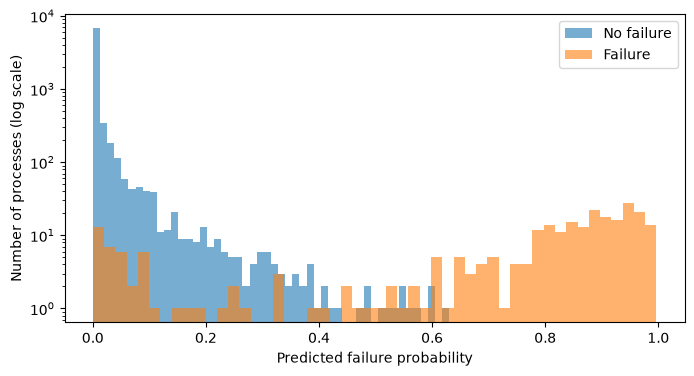

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.hist(proba[y == 0], bins=50, alpha=0.6, label="No failure")
plt.hist(proba[y == 1], bins=50, alpha=0.6, label="Failure")
plt.yscale("log")
plt.xlabel("Predicted failure probability")
plt.ylabel("Number of processes (log scale)")
plt.legend()
plt.show()

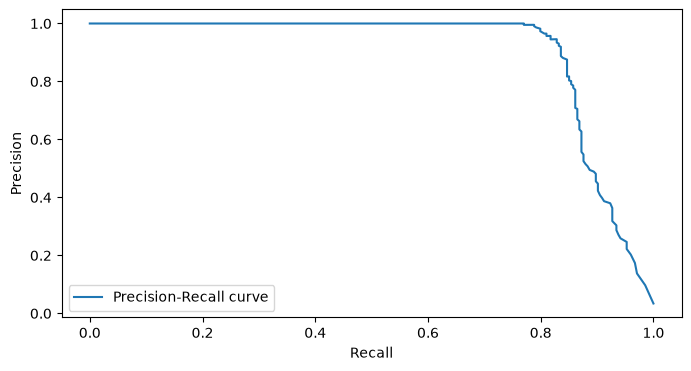

Threshold: 0.093
Precision: 0.507
Recall:    0.883


In [10]:
from sklearn.metrics import precision_recall_curve
import numpy as np

precision, recall, thresholds = precision_recall_curve(y, proba)

plt.figure(figsize=(8, 4))
plt.plot(recall, precision, label="Precision-Recall curve")  
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.show()

# precision y recall tienen un elemento más que thresholds: se quita el último
p = precision[:-1]
r = recall[:-1]

# Solo los umbrales que cumplen la precisión mínima
valid = p >= 0.5

# De esos, la posición del que tiene el recall más alto
best = np.argmax(r[valid])

best_threshold = thresholds[valid][best]
best_precision = p[valid][best]
best_recall = r[valid][best]

print(f"Threshold: {best_threshold:.3f}")
print(f"Precision: {best_precision:.3f}")
print(f"Recall:    {best_recall:.3f}")

In [12]:
thresholds_to_try = [0.05, 0.093, 0.1, 0.2, 0.3, 0.4, 0.5]

rows = []

for t in thresholds_to_try:
    pred = proba >= t

    detected = ((pred) & (y == 1)).sum()
    missed = ((~pred) & (y == 1)).sum()
    false_alarms = ((pred) & (y == 0)).sum()

    precision_t = detected / (detected + false_alarms)
    recall_t = detected / (detected + missed)

    rows.append({
        "threshold": t,
        "precision": precision_t,
        "recall": recall_t,
        "detected": detected,
        "missed": missed,
        "false_alarms": false_alarms,
    })

table = pd.DataFrame(rows)
print(table.round(3))

   threshold  precision  recall  detected  missed  false_alarms
0      0.050      0.380   0.923       253      21           413
1      0.093      0.507   0.883       242      32           235
2      0.100      0.525   0.876       240      34           217
3      0.200      0.722   0.861       236      38            91
4      0.300      0.844   0.847       232      42            43
5      0.400      0.931   0.832       228      46            17
6      0.500      0.957   0.814       223      51            10


In [13]:
pred = proba >= 0.093

mode_columns = ["tool_wear_failure", "heat_dissipation_failure", "power_failure",
                "overstrain_failure", "random_failure"]

rows = []
for mode in mode_columns:
    is_mode = (train[mode] == 1).to_numpy()
    rows.append({
        "mode": mode,
        "total": is_mode.sum(),
        "detected": (pred & is_mode).sum(),
    })

by_mode = pd.DataFrame(rows)
by_mode["recall"] = by_mode["detected"] / by_mode["total"]
print(by_mode.round(3))

                       mode  total  detected  recall
0         tool_wear_failure     37        13   0.351
1  heat_dissipation_failure     93        93   1.000
2             power_failure     79        79   1.000
3        overstrain_failure     75        75   1.000
4            random_failure     19         1   0.053


In [14]:
pred = proba >= 0.093

mode_columns = ["tool_wear_failure", "heat_dissipation_failure", "power_failure",
                "overstrain_failure", "random_failure"]

failure = (train["machine_failure"] == 1).to_numpy()
no_mode = failure & (train[mode_columns].sum(axis=1) == 0).to_numpy()

rows = []
for mode in mode_columns:
    is_mode = (train[mode] == 1).to_numpy() & failure      # solo los que son fallo de máquina
    rows.append({"mode": mode, "failures": is_mode.sum(), "detected": (pred & is_mode).sum()})

rows.append({"mode": "no mode flagged", "failures": no_mode.sum(), "detected": (pred & no_mode).sum()})

by_mode = pd.DataFrame(rows)
by_mode["recall"] = by_mode["detected"] / by_mode["failures"]
print(by_mode.round(3))

missed = failure & ~pred
print(f"Missed failures: {missed.sum()}")
print(f"Missed with TWF: {(missed & (train['tool_wear_failure'] == 1).to_numpy()).sum()}")
print(f"Missed with no mode: {(missed & no_mode).sum()}")

                       mode  failures  detected  recall
0         tool_wear_failure        37        13   0.351
1  heat_dissipation_failure        93        93   1.000
2             power_failure        79        79   1.000
3        overstrain_failure        75        75   1.000
4            random_failure         1         1   1.000
5           no mode flagged         8         0   0.000
Missed failures: 32
Missed with TWF: 24
Missed with no mode: 8
